<a href="https://colab.research.google.com/github/AloTerra80/Front_Aulas/blob/main/Projeto_Modulo7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('/content/top50.csv', encoding='latin-1')

In [4]:
df = df.rename(
    columns={
        'Unnamed: 0': 'Indice',
        'Track.Name': 'Musica',
        'Artist.Name': 'Artista',
        'Genre': 'Genero',
        'Beats.Per.Minute': 'BPM',
        'Energy': 'Energia',
        'Danceability': 'Dancabilidade',
        'Loudness..dB..': 'Volume_dB',
        'Liveness': 'Vivacidade',
        'Valence.': 'Valencia',
        'Length.': 'Duracao',
        'Acousticness..': 'Acustica',
        'Speechiness.': 'Vocabilidade',
        'Popularity': 'Popularidade',
    }
)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Indice         50 non-null     int64 
 1   Musica         50 non-null     object
 2   Artista        50 non-null     object
 3   Genero         50 non-null     object
 4   BPM            50 non-null     int64 
 5   Energia        50 non-null     int64 
 6   Dancabilidade  50 non-null     int64 
 7   Volume_dB      50 non-null     int64 
 8   Vivacidade     50 non-null     int64 
 9   Valencia       50 non-null     int64 
 10  Duracao        50 non-null     int64 
 11  Acustica       50 non-null     int64 
 12  Vocabilidade   50 non-null     int64 
 13  Popularidade   50 non-null     int64 
dtypes: int64(11), object(3)
memory usage: 5.6+ KB


#1. Aritistas mais populares?

In [6]:
df.loc[df['Popularidade'].idxmax(), ['Artista', 'Popularidade']]

,9
Artista,Billie Eilish
Popularidade,95


A artista Mais popular foi a Billie Eilish com 95 de popularidade

#2. Quais são os 5 artistas mais frequentes no top 50?

In [7]:
df['Artista'].value_counts().head(5)

,count
Artista,
Ed Sheeran,4
Shawn Mendes,2
Post Malone,2
Ariana Grande,2
Billie Eilish,2


Os aritistas Mais frequentes no Top 50 são Ed Sheeran, Shawn Mendes, Post Malone, Ariana Grande e Billie Eilish

#3. Qual Artista tem mais Danceabilidade?

In [8]:
df.loc[df['Dancabilidade'].idxmax(), ['Musica', 'Artista', 'Dancabilidade']]

,43
Musica,Talk
Artista,Khalid
Dancabilidade,90


A musica com maior indice de danceabilidade é a Talk de Khalid

#4. Qual a musica mais longa e a mais curta?

In [9]:
indices = [df['Duracao'].idxmax(), df['Duracao'].idxmin()]
df.loc[indices, ['Musica', 'Artista', 'Duracao']]

,Musica,Artista,Duracao
22,No Me Conoce - Remix,Jhay Cortez,309
21,Panini,Lil Nas X,115


A musica Mais longa é do Jhay Cirtez com 309, sendo No Me Conoce - Remix e a menor é de Lil Nas X com 115, sendo Panini

#5. Qual é a distribuilção de popularidade das Musicas?

In [10]:
df['Popularidade'].describe()

,Popularidade
count,50.000000
mean,87.500000
std,4.491489
min,70.000000
25%,86.000000
50%,88.000000
75%,90.750000
max,95.000000


O minimo foi de 70 pontos e o maior de 95 ponmtos

#6. Qual o gênero/Artista com maior Energy médio

In [11]:
df.groupby('Artista')['Energia'].mean().sort_values(ascending=False).head()

,Energia
Artista,
Katy Perry,88.0
Daddy Yankee,86.0
Anuel AA,81.0
Jhay Cortez,79.0
Lunay,78.0


A Artista é a Katy Perry com 88 pontos de energia

# 7. A Média de Batidas Por minuto?

In [12]:
df['BPM'].mean()

np.float64(120.06)

A média de Batidas Por minuto é 120.06

#8. Músicas com valencia (positividade) Mais alto e Mais Baixo

In [13]:
Lista = [df['Valencia'].idxmax(), df['Valencia'].idxmin()]
df.loc[Lista, ['Musica', 'Artista', 'Valencia']]

,Musica,Artista,Valencia
38,Sucker,Jonas Brothers,95
14,Money In The Grave (Drake ft. Rick Ross),Drake,10


A musica com maior valencia é Sucker com 95 e a menor é Money In The Grave (Drake ft. Rick Ross) com 10

#9. Correlação entre Energy e Loudness(Volume Baixo)

In [14]:
df[['Energia', 'Volume_dB']].corr()

,Energia,Volume_dB
Energia,1.000000,0.670794
Volume_dB,0.670794,1.000000


#10. Contagem de gêneros musicais. Quantos Temos no Dataset

In [15]:
df['Genero'].value_counts()

,count
Genero,
dance pop,8
pop,7
latin,5
canadian hip hop,3
edm,3
dfw rap,2
reggaeton flow,2
canadian pop,2
country rap,2


# **Visualização Dos Dados**

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

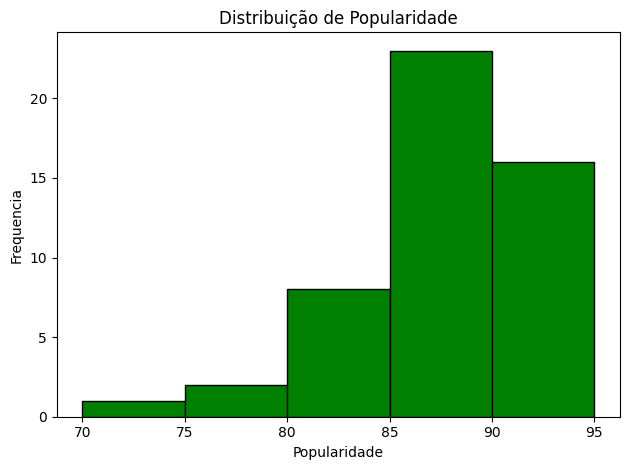

In [17]:
plt.hist(df['Popularidade'], bins=5, color='green', edgecolor='black')
plt.title('Distribuição de Popularidade')
plt.xlabel('Popularidade')
plt.ylabel('Frequencia')
plt.tight_layout()
plt.show()

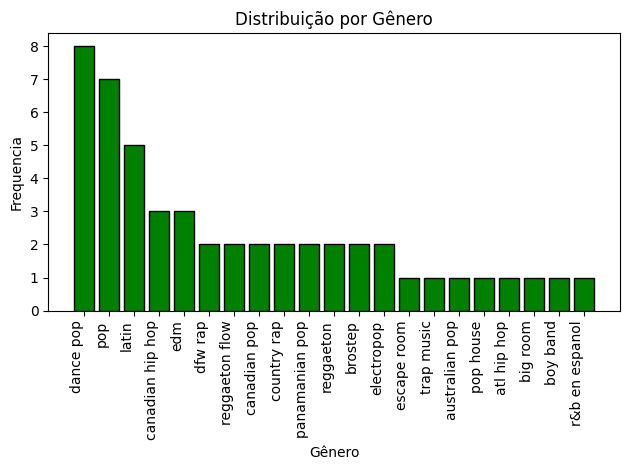

In [18]:
plt.bar(
    df['Genero'].value_counts().index,
    df['Genero'].value_counts().values,
    color='green',
    edgecolor='black',
)
plt.title('Distribuição por Gênero')
plt.xlabel('Gênero')
plt.ylabel('Frequencia')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

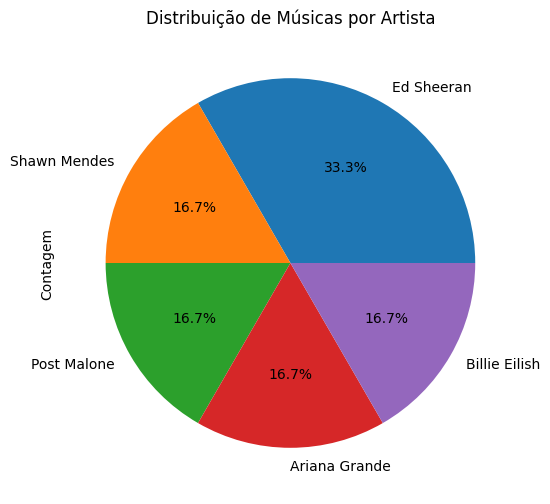

In [36]:

df['Artista'].value_counts().head(5).plot(
    kind='pie', figsize=(8, 6), autopct='%1.1f%%'
)
plt.title('Distribuição de Músicas por Artista')
plt.ylabel('Contagem')
plt.show()

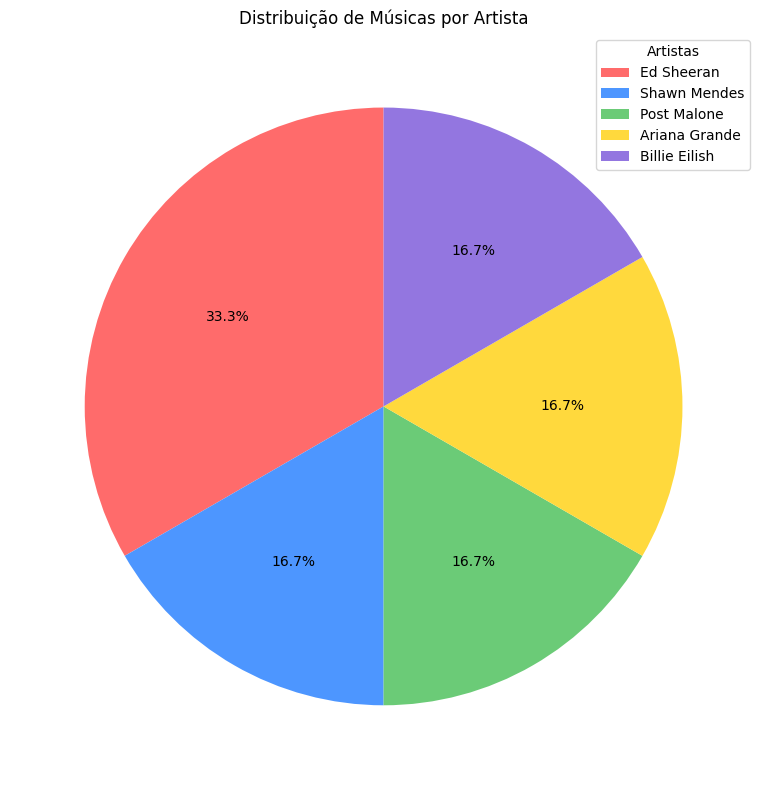

In [39]:
top_artistas = df['Artista'].value_counts().head(5)

cores = ['#FF6B6B', '#4D96FF', '#6BCB77', '#FFD93D', '#9376E0']

plt.figure(figsize=(10, 8))
plt.pie(
    top_artistas, colors=cores, autopct='%1.1f%%', startangle=90
)
plt.title('Distribuição de Músicas por Artista')


plt.legend(top_artistas.index, title='Artistas', loc='best')
plt.tight_layout()
plt.show()